# SuperStore Sales & Profitability Analysis
Where does a retail business make and lose money? Dataset: 9,994 order lines, 2014-2017 (Sample - Superstore).

In [1]:
import pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
df = pd.read_csv('data/Sample - Superstore.csv', encoding='latin-1')
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')
print(df.shape, '| nulls:', df.isna().sum().sum(), '| duplicates:', df.duplicated().sum())
df.head(3)

(9994, 21) | nulls: 0 | duplicates: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714


## 1. Headline KPIs

In [2]:
sales, profit = df.Sales.sum(), df.Profit.sum()
print(f'Sales ${sales:,.0f} | Profit ${profit:,.0f} | Margin {profit/sales:.1%}')
print(f"Orders {df['Order ID'].nunique():,} | Customers {df['Customer ID'].nunique():,}")
loss = df[df.Profit < 0]
print(f'Loss-making lines: {len(loss):,} ({len(loss)/len(df):.1%}), total loss ${loss.Profit.sum():,.0f}')

Sales $2,297,201 | Profit $286,397 | Margin 12.5%
Orders 5,009 | Customers 793
Loss-making lines: 1,871 (18.7%), total loss $-156,131


In [3]:
def summarise(col):
    t = df.groupby(col).agg(Sales=('Sales','sum'), Profit=('Profit','sum'), AvgDiscount=('Discount','mean'))
    t['Margin'] = t.Profit / t.Sales
    return t.sort_values('Profit')
summarise('Region')

,Sales,Profit,AvgDiscount,Margin
Region,,,,
Central,501239.8908,39706.3625,0.240353,0.079216
South,391721.9050,46749.4303,0.147253,0.119343
East,678781.2400,91522.7800,0.145365,0.134834
West,725457.8245,108418.4489,0.109335,0.149448


## 2. Category and sub-category profitability

In [4]:
summarise('Category')

,Sales,Profit,AvgDiscount,Margin
Category,,,,
Furniture,741999.7953,18451.2728,0.173923,0.024867
Office Supplies,719047.0320,122490.8008,0.157285,0.170352
Technology,836154.0330,145454.9481,0.132323,0.173957


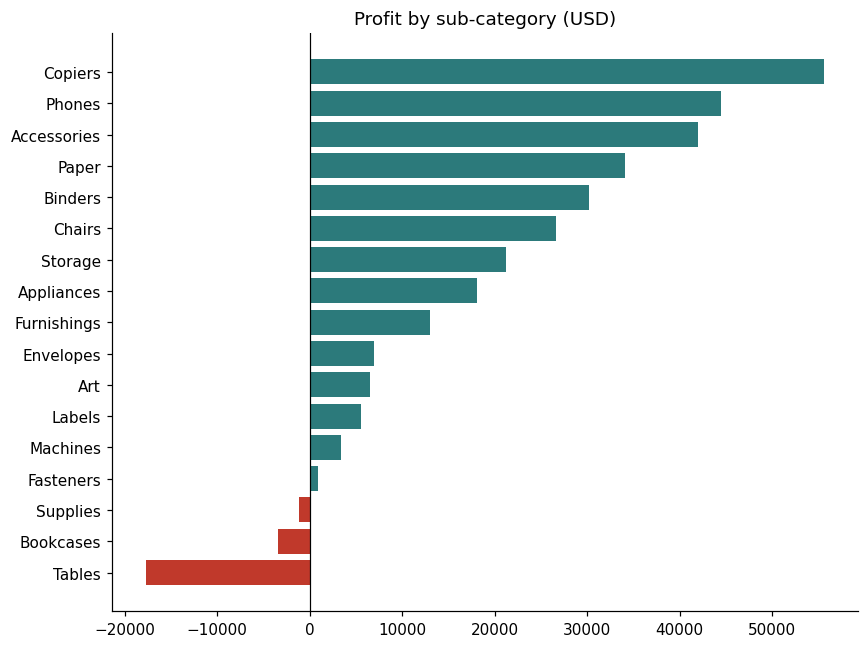

In [5]:
sub = summarise('Sub-Category')
fig, ax = plt.subplots(figsize=(8,6))
ax.barh(sub.index, sub.Profit, color=['#c0392b' if v<0 else '#2c7a7b' for v in sub.Profit])
ax.set_title('Profit by sub-category (USD)'); ax.axvline(0,color='k',lw=.8)
plt.tight_layout(); plt.savefig('images/profit_by_subcategory.png'); plt.show()

## 3. Discounting is the main driver of losses

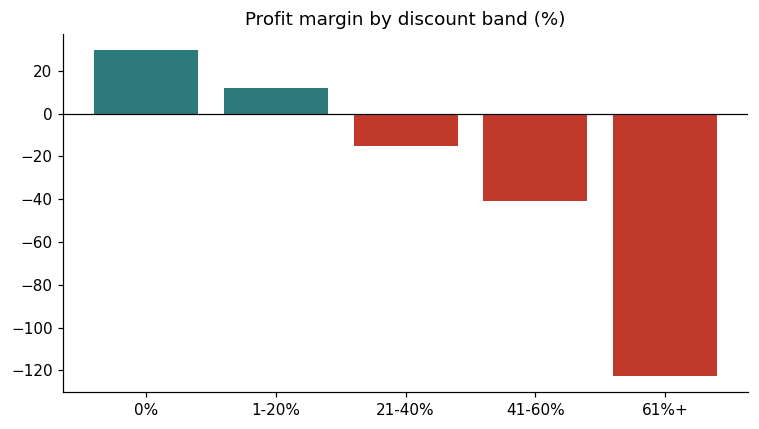

,Sales,Profit,Lines,Margin
DiscountBand,,,,
0%,1087908.470,320987.603,4798,0.295
1-20%,846522.240,100785.474,3803,0.119
21-40%,234137.898,-35817.466,460,-0.153
41-60%,71048.214,-28944.194,215,-0.407
61%+,57584.038,-70614.396,718,-1.226


In [6]:
df['DiscountBand'] = pd.cut(df.Discount, [-.01,0,.2,.4,.6,1], labels=['0%','1-20%','21-40%','41-60%','61%+'])
d = df.groupby('DiscountBand', observed=True).agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Lines=('Sales','size'))
d['Margin'] = d.Profit / d.Sales
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(d.index.astype(str), d.Margin*100, color=['#c0392b' if v<0 else '#2c7a7b' for v in d.Margin])
ax.set_title('Profit margin by discount band (%)'); ax.axhline(0,color='k',lw=.8)
plt.tight_layout(); plt.savefig('images/margin_by_discount.png'); plt.show()
d.round(3)

In [7]:
hi = df[df.Discount > 0.2]
print(f'Lines discounted >20%: {len(hi):,} | unprofitable: {(hi.Profit<0).mean():.1%} | total profit ${hi.Profit.sum():,.0f}')

Lines discounted >20%: 1,393 | unprofitable: 96.8% | total profit $-135,376


## 4. Where are the losses? (states)

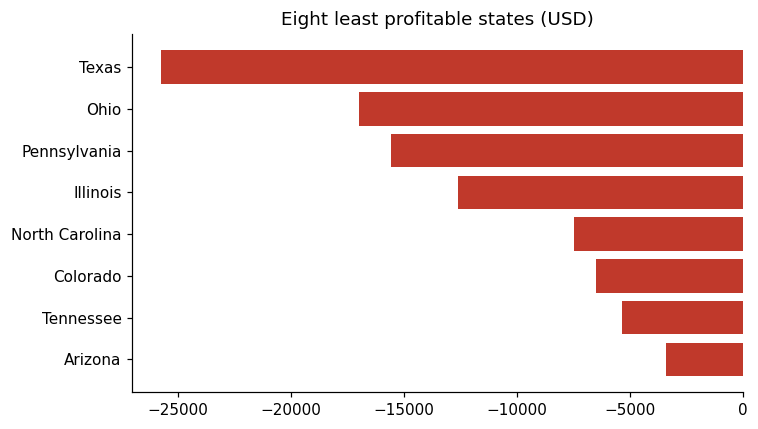

,Sales,Profit,AvgDiscount,Margin
State,,,,
Texas,170188.046,-25729.356,0.370,-0.151
Ohio,78258.136,-16971.377,0.325,-0.217
Pennsylvania,116511.914,-15559.960,0.329,-0.134
Illinois,80166.101,-12607.887,0.390,-0.157
North Carolina,55603.164,-7490.912,0.284,-0.135
Colorado,32108.118,-6527.858,0.316,-0.203
Tennessee,30661.873,-5341.694,0.291,-0.174
Arizona,35282.001,-3427.925,0.304,-0.097


In [8]:
st = summarise('State')
worst = st.head(8)
fig, ax = plt.subplots(figsize=(7,4))
ax.barh(worst.index[::-1], worst.Profit[::-1], color='#c0392b')
ax.set_title('Eight least profitable states (USD)')
plt.tight_layout(); plt.savefig('images/worst_states.png'); plt.show()
worst[['Sales','Profit','AvgDiscount','Margin']].round(3)

## 5. Trend

In [9]:
y = df.groupby(df['Order Date'].dt.year).agg(Sales=('Sales','sum'), Profit=('Profit','sum'))
y['Margin'] = y.Profit / y.Sales
y.round(3)

,Sales,Profit,Margin
Order Date,,,
2014,484247.498,49543.974,0.102
2015,470532.509,61618.604,0.131
2016,609205.598,81795.174,0.134
2017,733215.255,93439.270,0.127


## Key findings
1. Overall margin is 12.5% ($286K profit on $2.30M sales), but 18.7% of order lines lose money.
2. Tables, Bookcases and Supplies are loss-making; Tables lose $17.7K at a -8.6% margin.
3. Orders discounted above 20% were unprofitable 97% of the time (1,393 lines, -$135K combined). Undiscounted orders earn a 29.5% margin.
4. Central region margin is 7.9% against 14.9% in West; Texas, Ohio, Pennsylvania and Illinois are the biggest loss-making states.
5. Furniture earns 2.5% margin versus 17% for Office Supplies and Technology.

## Recommendations
- Cap discounts at 20% and require approval above that.
- Review pricing and discounting on Tables and Bookcases.
- Investigate the Central region and the four loss-making states for discount-heavy accounts.